In [80]:
import math
import re
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_curve, roc_auc_score

import pickle

#Loading the dataset
!wget -q -O cardiovascular_dataset.zip \
"https://www.kaggle.com/api/v1/datasets/download/sulianova/cardiovascular-disease-dataset"

import zipfile

with zipfile.ZipFile(
    "cardiovascular_dataset.zip",
    "r"
) as zip_ref:

    zip_ref.extractall("cardiovascular_data")

df = pd.read_csv(
    "cardiovascular_data/cardio_train.csv",
    sep=";"
)

list(df.columns)

['id',
 'age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'cardio']

In [81]:
pd.concat([df.head(5), df.sample(5), df.tail(5)])

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
45995,65692,18239,1,165,68.0,100,60,1,1,0,0,0,0
11545,16508,15426,2,174,87.0,140,90,1,1,0,0,1,1
53209,75905,22495,1,162,74.0,120,70,1,1,0,0,0,0
43304,61871,23264,2,180,108.0,160,90,1,2,0,0,1,0
29783,42582,22606,2,173,69.0,120,80,1,1,0,0,1,0


In [82]:
df.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


# **Preprocessing**

unique values

In [84]:
pd.DataFrame([ df.nunique(), df.dtypes ], index=['Unique Values', 'Data Types'])

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
Unique Values,70000,8076,2,109,287,153,157,3,3,2,2,2,2
Data Types,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64


In [85]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

In [86]:
TARGET = 'cardio'

INPUT_FEATURES = [
    'id', 'age', 'gender', 'height', 'weight',
    'ap_hi', 'ap_lo', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active'
]

# Check the dataset
pd.DataFrame(
    [df.nunique(), df.dtypes],
    index=['Unique Values', 'Data Types']
)

# Check for duplicate rows
duplicates = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicates}")

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print(f"Dataset shape after removing duplicates: {df.shape}")

# Check for missing values
pd.DataFrame(
    {
        "Count": df.isna().sum().sort_values(ascending=False),
        "percent %": 100.0 * df.isna().sum().sort_values(ascending=False) / len(df),
    }
).T

# Check categorical values for consistency
for col in ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())

# Function for removing unwanted features
def drop_unwanted_features(df, feature_to_drop):
    print(f"\nDropping feature: {feature_to_drop}")

    if feature_to_drop in df.columns:
        df = df.drop(columns=[feature_to_drop])

    if feature_to_drop in INPUT_FEATURES:
        INPUT_FEATURES.remove(feature_to_drop)

    return df

# Remove ID because it is an identifier, not a predictive feature
df = drop_unwanted_features(df, 'id')

Number of duplicate rows: 0
Dataset shape after removing duplicates: (70000, 13)

gender
gender
1    45530
2    24470
Name: count, dtype: int64

cholesterol
cholesterol
1    52385
2     9549
3     8066
Name: count, dtype: int64

gluc
gluc
1    59479
2     5190
3     5331
Name: count, dtype: int64

smoke
smoke
0    63831
1     6169
Name: count, dtype: int64

alco
alco
0    66236
1     3764
Name: count, dtype: int64

active
active
0    13739
1    56261
Name: count, dtype: int64

cardio
cardio
0    35021
1    34979
Name: count, dtype: int64

Dropping feature: id


In [87]:
# Check blood pressure consistency

invalid_bp = df['ap_lo'] >= df['ap_hi']

print(
    f"Records where diastolic BP >= systolic BP: "
    f"{invalid_bp.sum()}"
)

# Remove invalid BP records
df = df[df['ap_lo'] < df['ap_hi']].copy()

print(f"Dataset shape after BP cleaning: {df.shape}")

Records where diastolic BP >= systolic BP: 1236
Dataset shape after BP cleaning: (68764, 12)


In [88]:
list(df.columns)

['age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'cardio']

Outliers

In [89]:
def find_iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return (series < lower) | (series > upper)


outlier_features = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']

# Detect outliers per feature and report counts
outlier_flags = pd.DataFrame({
    feature: find_iqr_outliers(df[feature])
    for feature in outlier_features
})

print("Outliers detected per feature:")
for feature in outlier_features:
    n_outliers = outlier_flags[feature].sum()
    pct_outliers = 100 * outlier_flags[feature].mean()
    print(f"  {feature}: {n_outliers} outliers ({pct_outliers:.2f}%)")

row_is_outlier = outlier_flags.any(axis=1)

print(
    f"\nRows flagged as outliers overall: "
    f"{row_is_outlier.sum()} ({100 * row_is_outlier.mean():.2f}% of dataset)"
)

# Remove outlier rows
df = df[~row_is_outlier].reset_index(drop=True)

print(f"Dataset shape after outlier removal: {df.shape}")

Outliers detected per feature:
  age: 4 outliers (0.01%)
  height: 506 outliers (0.74%)
  weight: 1746 outliers (2.54%)
  ap_hi: 1058 outliers (1.54%)
  ap_lo: 3570 outliers (5.19%)

Rows flagged as outliers overall: 6265 (9.11% of dataset)
Dataset shape after outlier removal: (62499, 12)


In [90]:
print(df.head(10))

     age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  smoke  \
0  18393       2     168    62.0    110     80            1     1      0   
1  20228       1     156    85.0    140     90            3     1      0   
2  18857       1     165    64.0    130     70            3     1      0   
3  17623       2     169    82.0    150    100            1     1      0   
4  21914       1     151    67.0    120     80            2     2      0   
5  22113       1     157    93.0    130     80            3     1      0   
6  22584       2     178    95.0    130     90            3     3      0   
7  17668       1     158    71.0    110     70            1     1      0   
8  22530       1     169    80.0    120     80            1     1      0   
9  18815       2     173    60.0    120     80            1     1      0   

   alco  active  cardio  
0     0       1       0  
1     0       1       1  
2     0       0       1  
3     0       1       1  
4     0       0       0  
5     0

# EDA & Dataset Visualization

Barcharts

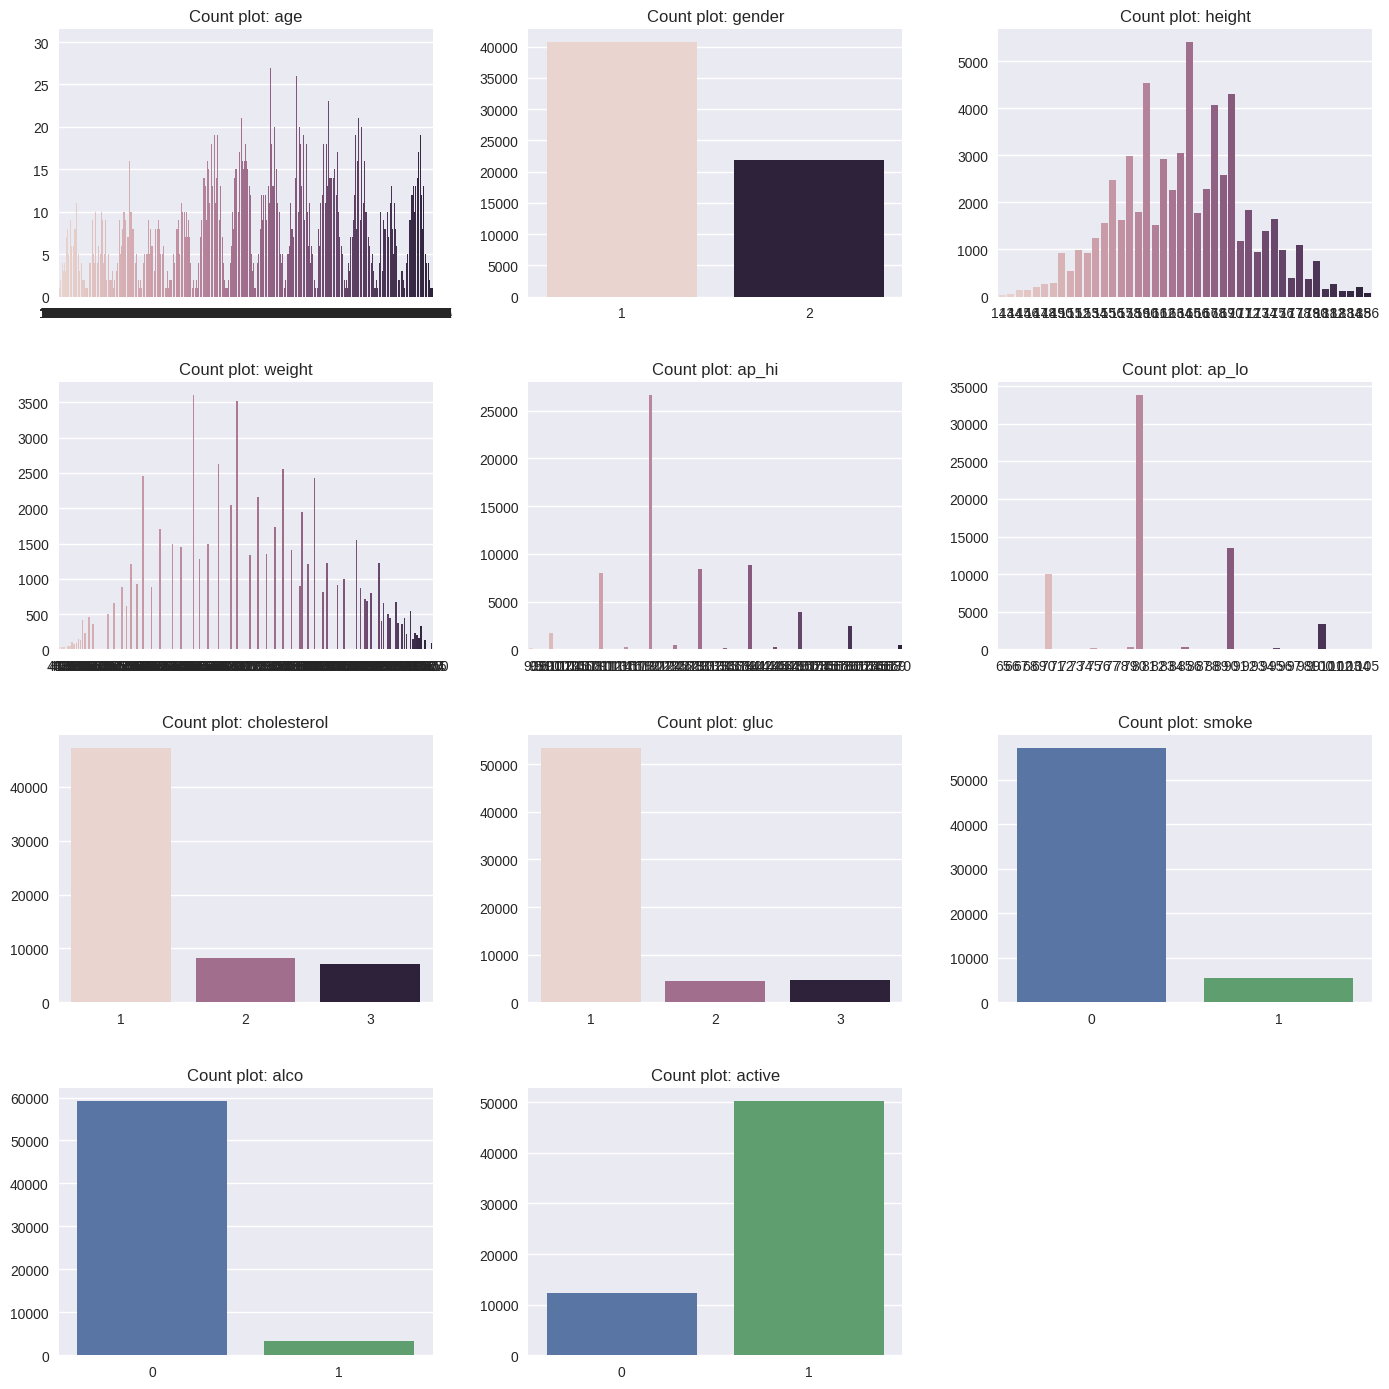

In [91]:
plt.style.use(plt.style.available[12])

N_COLS = 3
N_ROWS = math.ceil(len(INPUT_FEATURES) / N_COLS)

plt.figure(figsize=(14, 3.5 * N_ROWS))

for i, cat_feature in enumerate(INPUT_FEATURES):
    plt.subplot(N_ROWS, N_COLS, i+1)
    plt.title(f"Count plot: {cat_feature}")
    sns.countplot(data=df, x=cat_feature, hue=cat_feature, legend=False)
    plt.ylabel("")
    plt.xlabel('')

plt.tight_layout(h_pad=3.0, w_pad=2.0)

plt.show()

# **Histograms -Missing**

Count of CVD vs No CVD

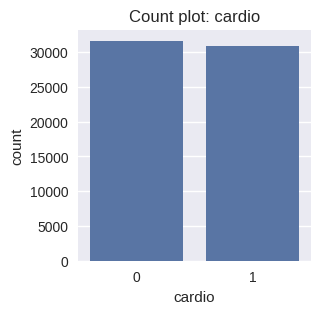

In [92]:
plt.figure(figsize=(3,3))
plt.title(f"Count plot: {TARGET}")
sns.countplot(df, x=TARGET)
plt.show()

Kernel Density Estimate (KDE) plots

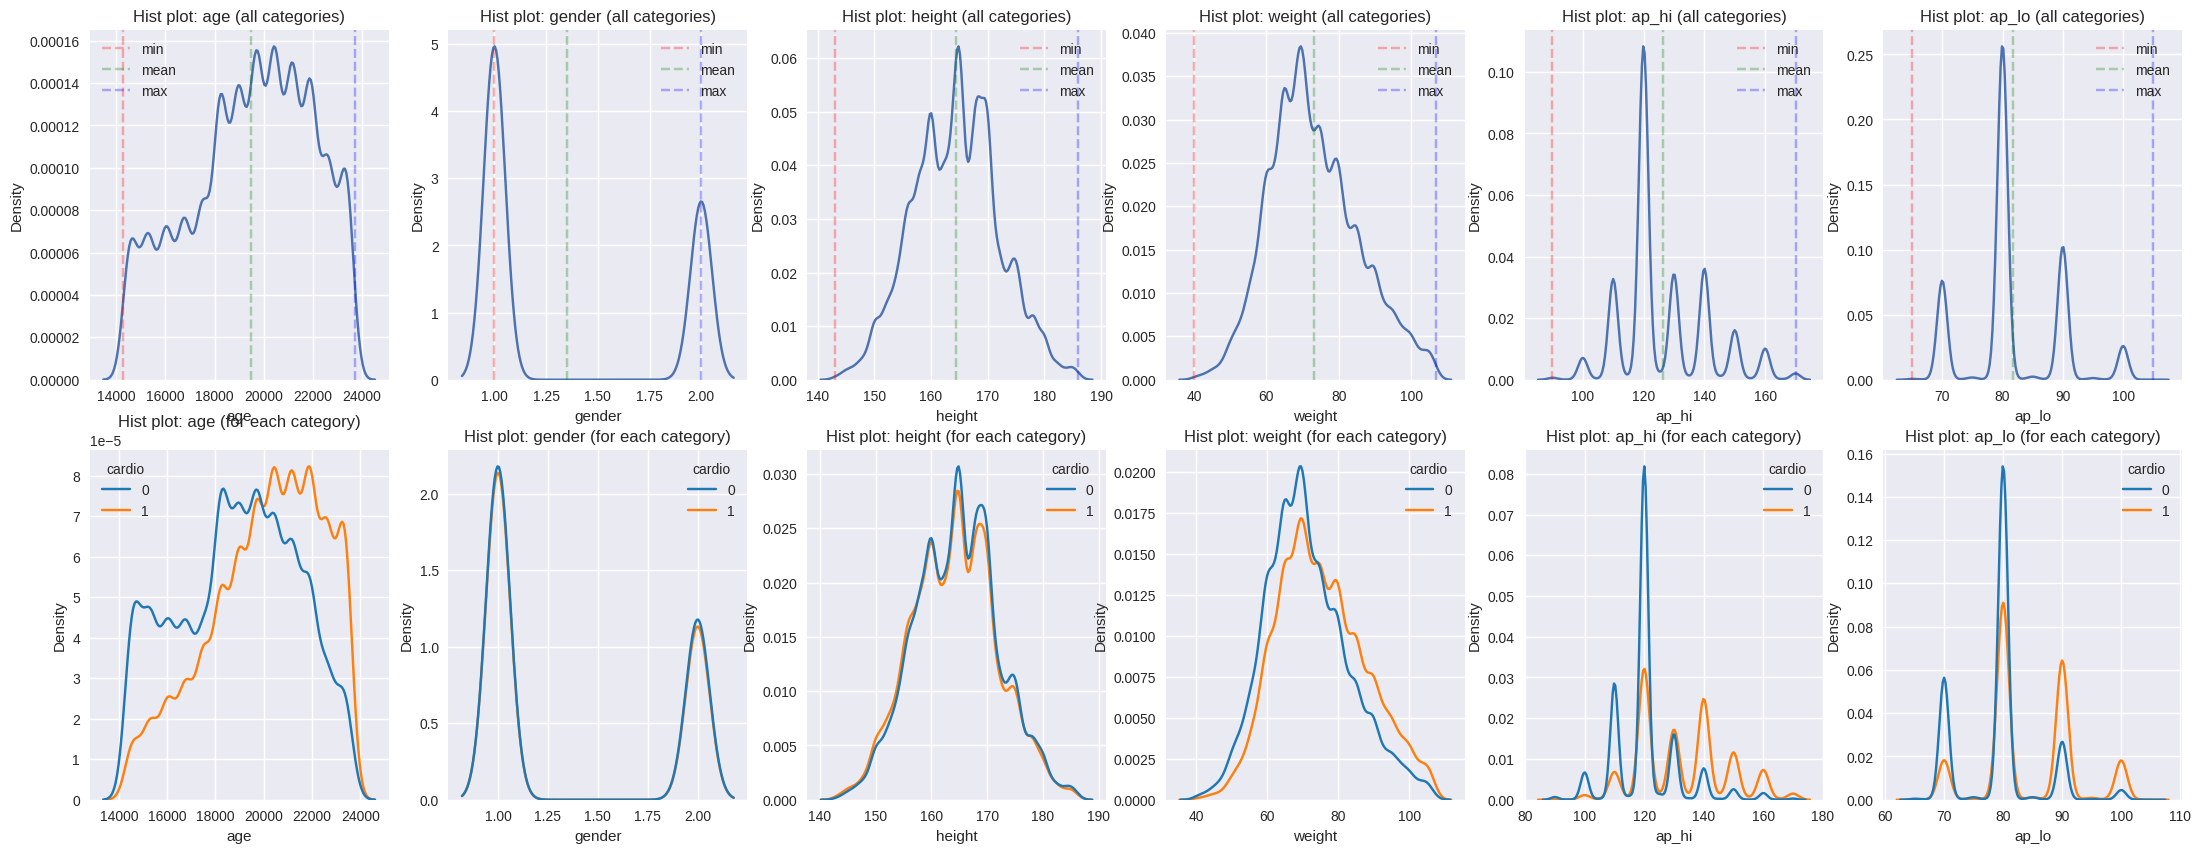

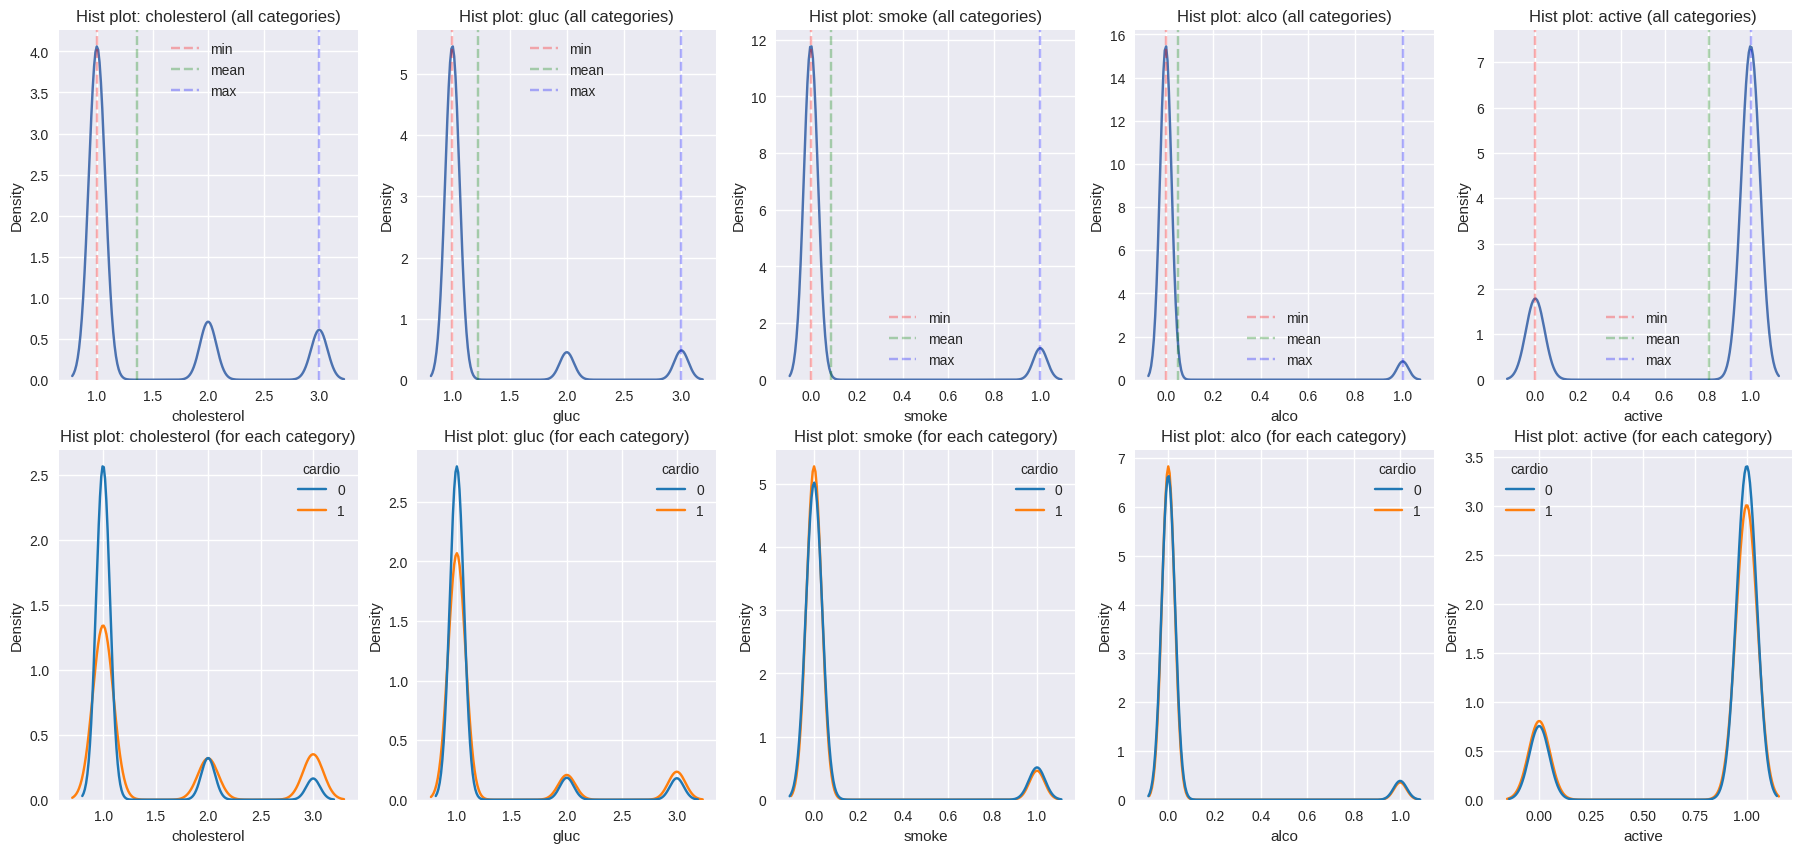

In [93]:
ROW_WIDTH = 6
temp = 0

numeric_features = [
    feature for feature in INPUT_FEATURES
    if df[feature].dtype in ['int64', 'float64', 'int32', 'float32']
    and feature not in ['bmi_category', 'hypertension_stage']
]

for num_feature in numeric_features:
    if temp == 0:
        plt.figure(figsize=(27,10))

    plt.subplot(2,ROW_WIDTH, temp + 1)
    plt.title(f"Hist plot: {num_feature} (all categories)")
    sns.kdeplot(df, x=num_feature, )

    plt.axvline(x= df[num_feature].min() , label="min", color='r', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].mean() , label="mean", color='g', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].max() , label="max", color='b', linestyle='--', alpha = 0.3)

    plt.legend()


    plt.subplot(2,ROW_WIDTH, (temp + 1) + ROW_WIDTH)
    plt.title(f"Hist plot: {num_feature} (for each category)")
    sns.kdeplot(df, x=num_feature, hue=TARGET, palette='tab10')

    if temp == ROW_WIDTH - 1:
        plt.show()

    temp = (temp + 1) % ROW_WIDTH

if temp != ROW_WIDTH - 1:
    plt.show()

Box-plots

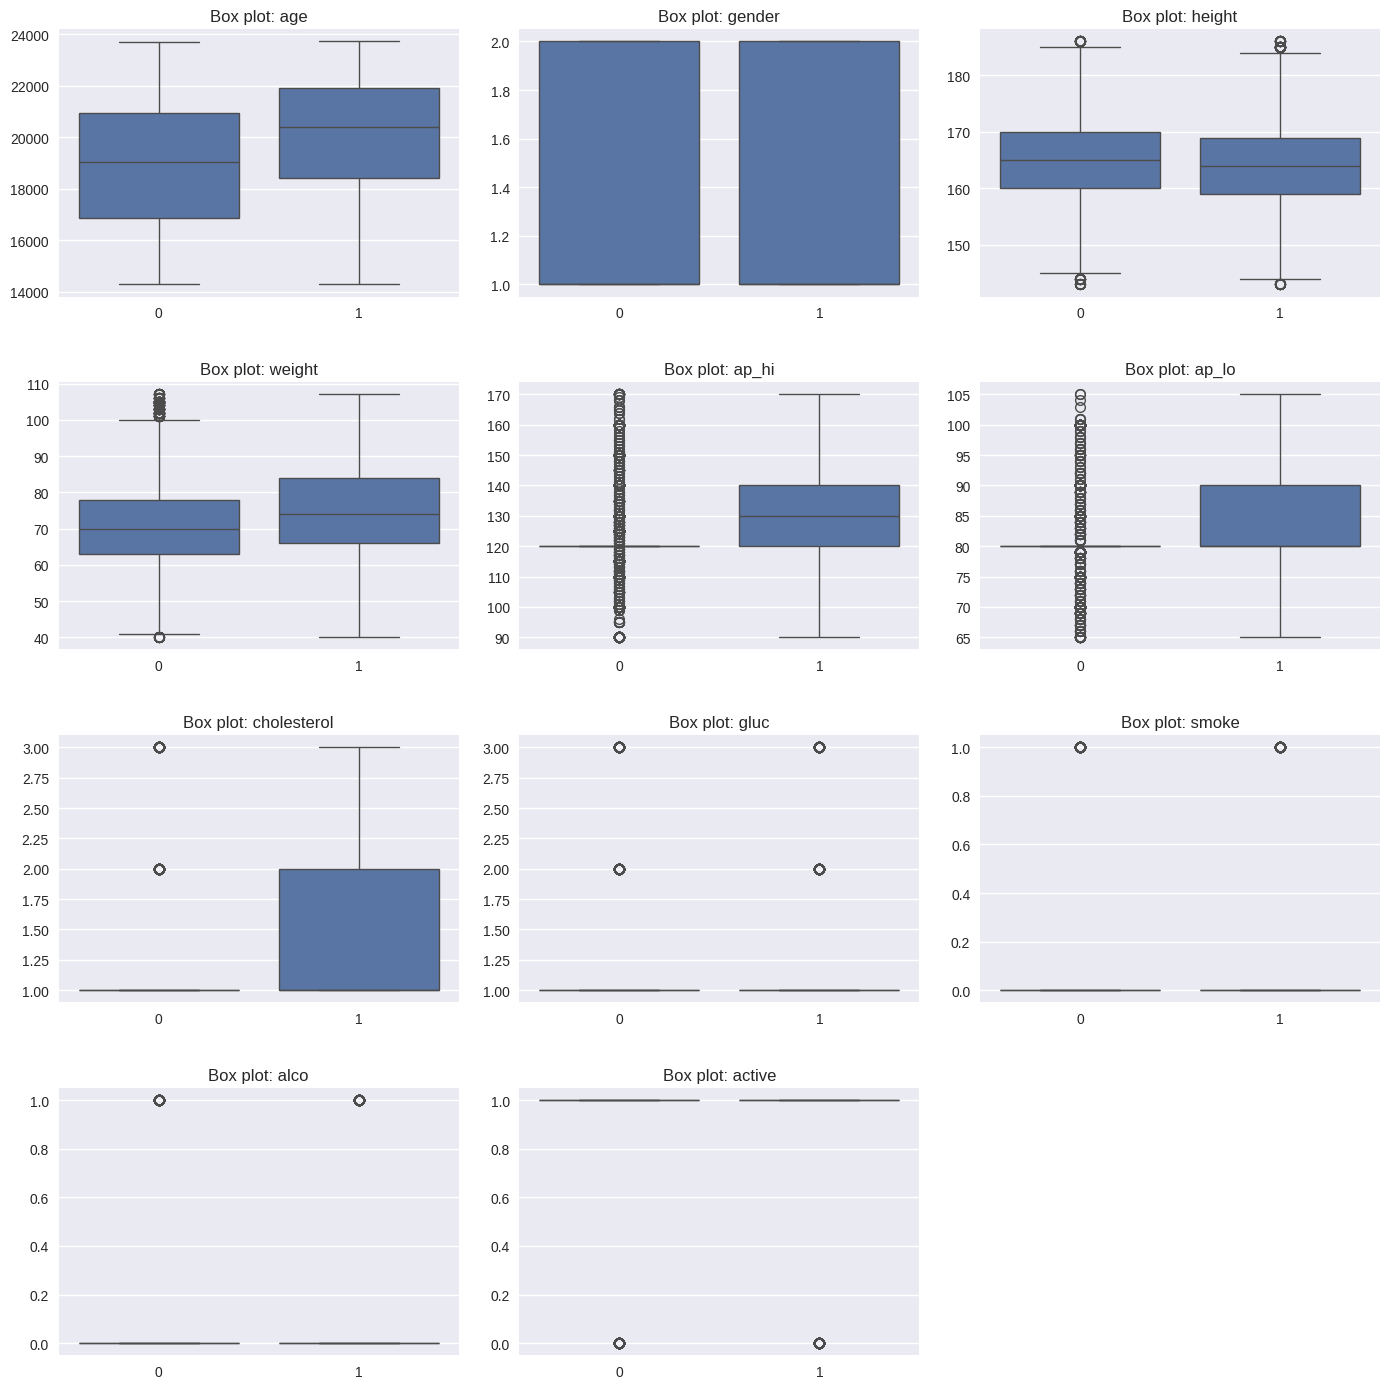

In [94]:
N_COLS = 3
N_ROWS = math.ceil(len(INPUT_FEATURES) / N_COLS)

plt.figure(figsize=(14, 3.5 * N_ROWS))

for i, feature in enumerate(INPUT_FEATURES):
    plt.subplot(N_ROWS, N_COLS, i+1)
    plt.title(f"Box plot: {feature}")
    sns.boxplot(df, x=TARGET, y=feature)
    plt.ylabel("")
    plt.xlabel('')

plt.tight_layout(h_pad=3.0, w_pad=2.0)
plt.show()

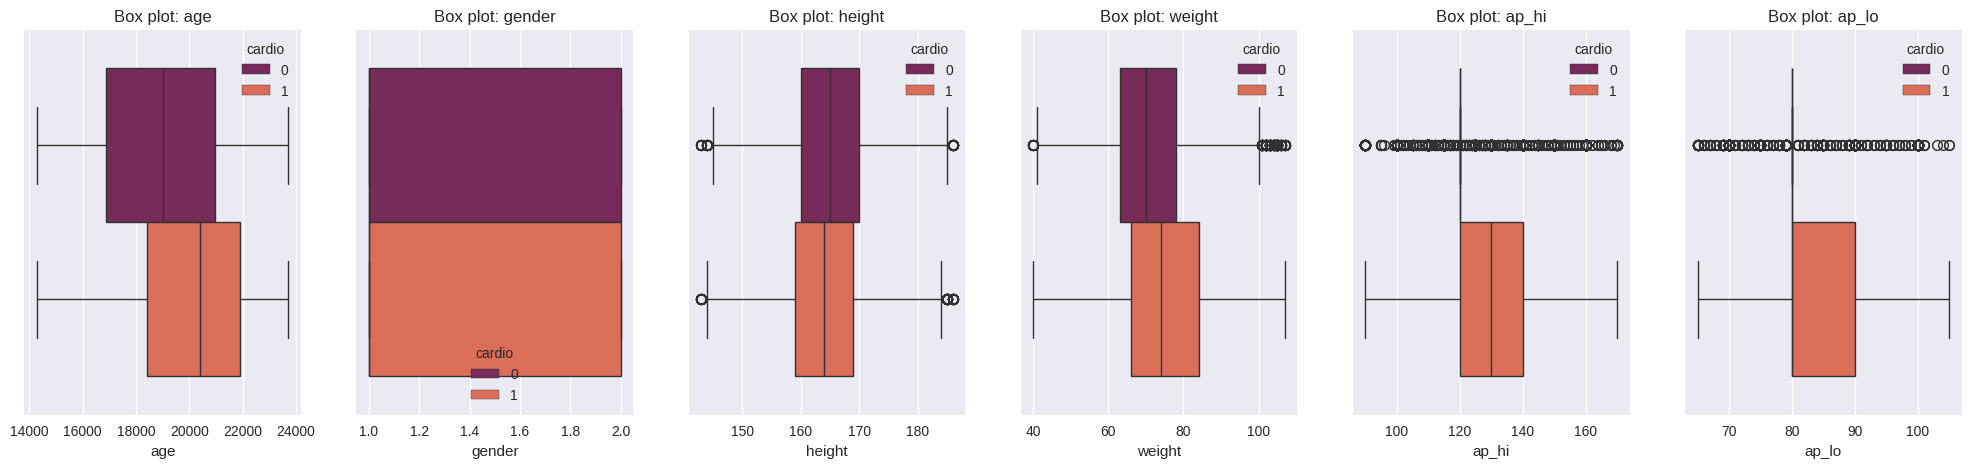

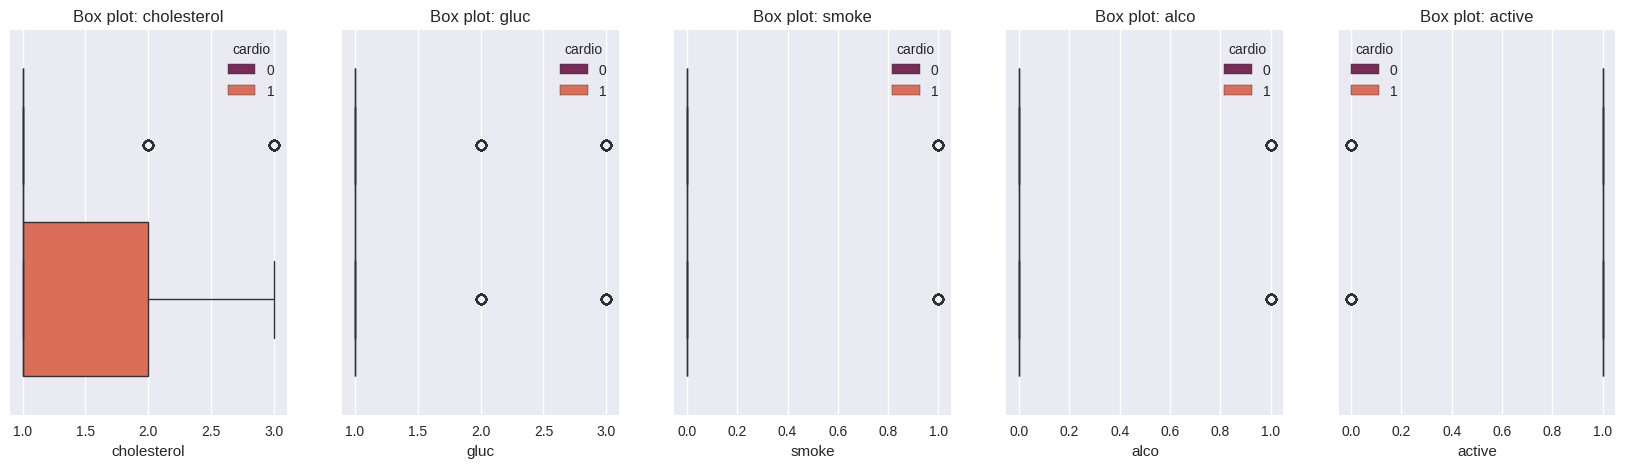

In [95]:
def plot_box(features, hue):
    ROW_WIDTH = 6
    temp = 0

    for num_feature in features:
        if temp == 0:
            plt.figure(figsize=(25,5))

        plt.subplot(1,ROW_WIDTH, temp + 1)
        plt.title(f"Box plot: {num_feature}")
        sns.boxplot(df, x=num_feature, hue=hue, palette='rocket')

        if temp == ROW_WIDTH - 1:
            plt.show()

        temp = (temp + 1) % ROW_WIDTH

    if temp != ROW_WIDTH - 1:
        plt.show()

plot_box(INPUT_FEATURES, TARGET)

Scatter-plots

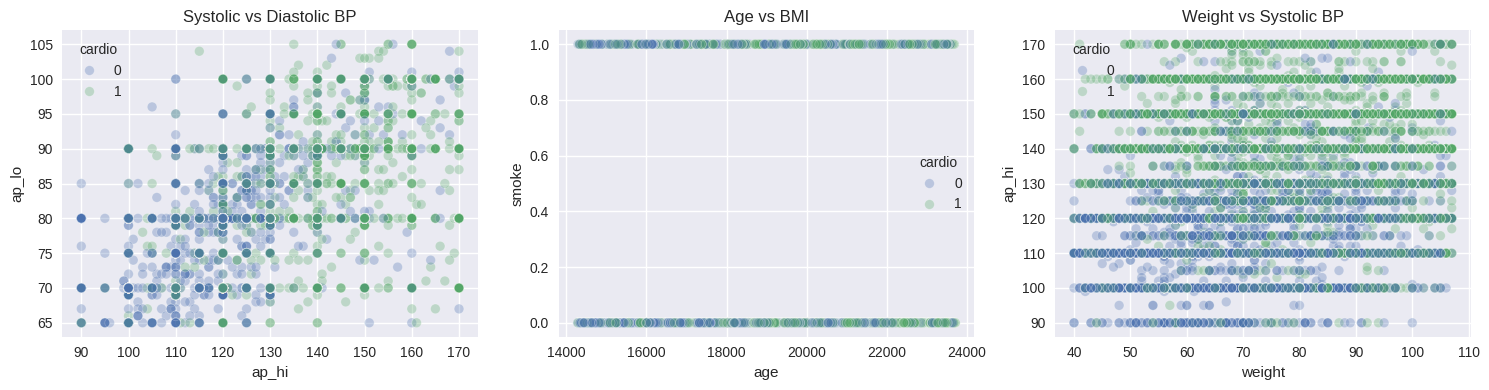

In [96]:
#Scatter plots
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
sns.scatterplot(df, x='ap_hi', y='ap_lo', hue=TARGET, alpha=0.3)
plt.title("Systolic vs Diastolic BP")

plt.subplot(1,3,2)
sns.scatterplot(df, x='age', y='smoke', hue=TARGET, alpha=0.3)
plt.title("Age vs BMI")

plt.subplot(1,3,3)
sns.scatterplot(df, x='weight', y='ap_hi', hue=TARGET, alpha=0.3)
plt.title("Weight vs Systolic BP")

plt.tight_layout()
plt.show()

Confusion Matrix

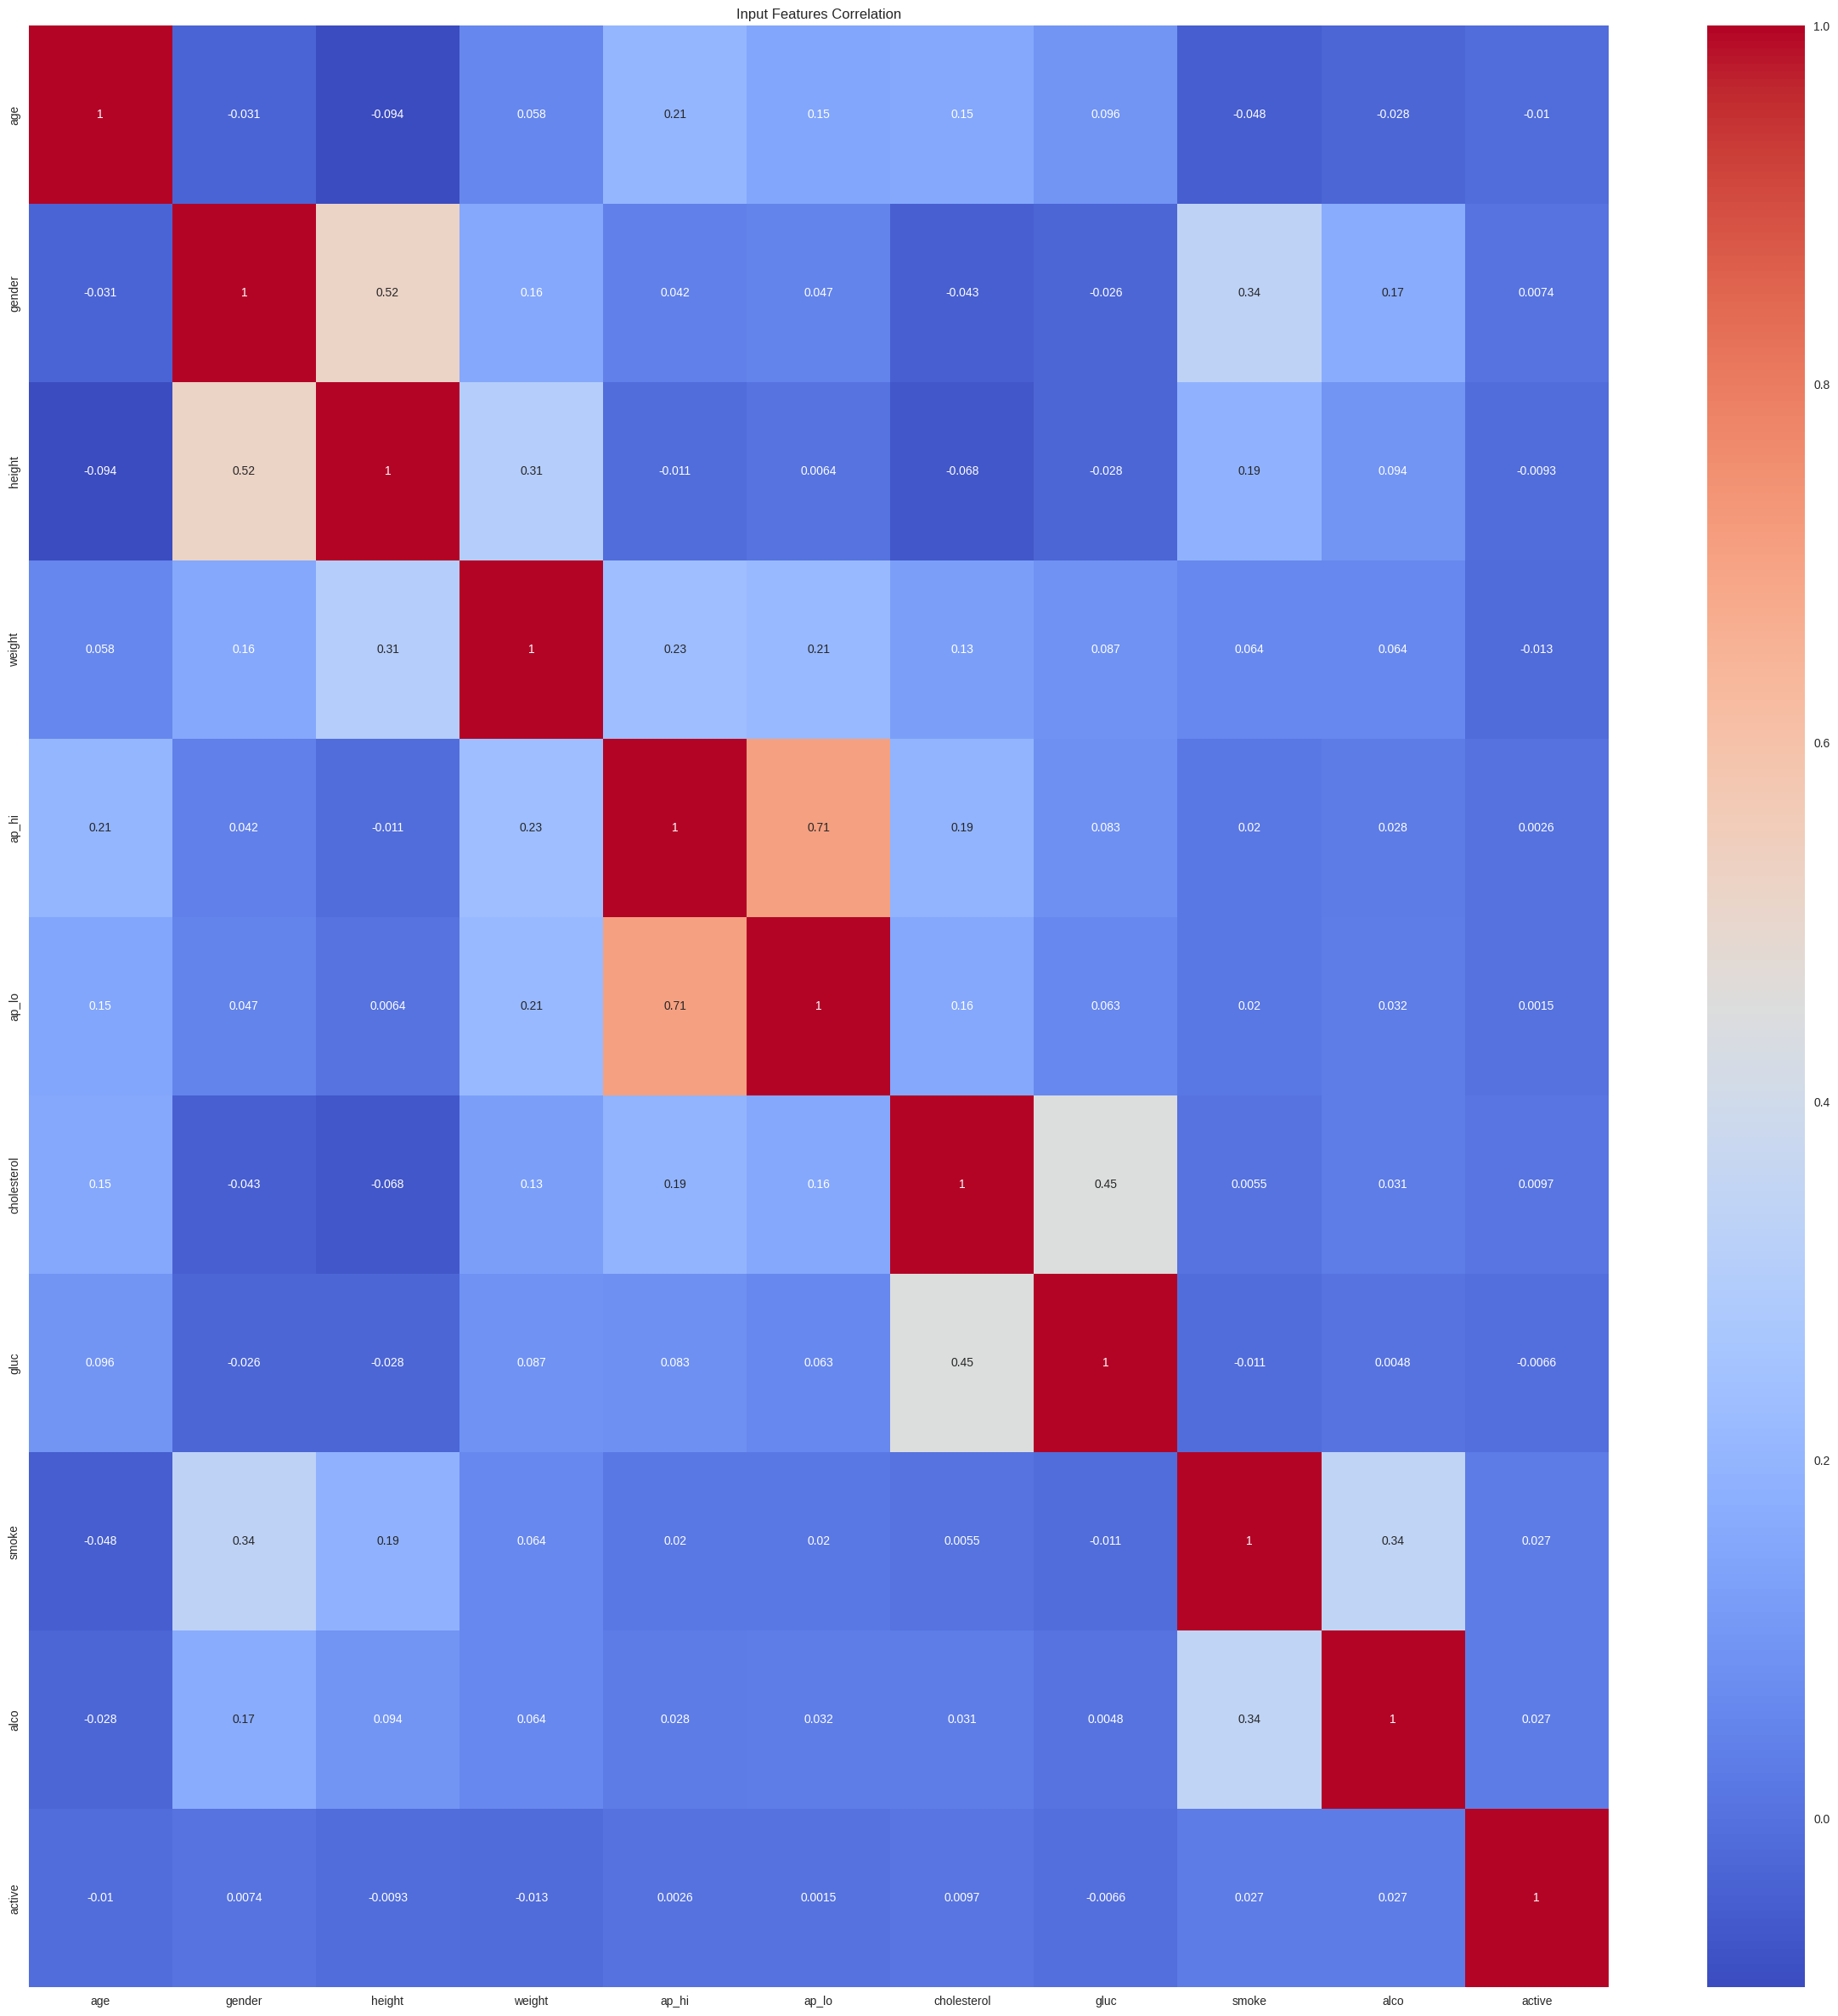

In [97]:
plt.figure(figsize=(30, 30))

plt.title("Input Features Correlation")

sns.heatmap(
    df[INPUT_FEATURES].corr(),
    annot=True,
    cmap='coolwarm',
    )

plt.show()

# **Feature Engineering**

In [98]:
INPUT_FEATURES

['age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active']

In [99]:
df.head(5)

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,21914,1,151,67.0,120,80,2,2,0,0,0,0


In [100]:
df['age_years'] = (df['age'] / 365).round().astype(int)

In [101]:
df['height'] = df['height'] / 100

In [102]:
df['bmi'] = df['weight'] / ((df['height'] / 100) ** 2)

In [103]:
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']

In [104]:
df['health_index'] = (df['active'] * 1) - (df['smoke'] * 0.5) - (df['alco'] * 0.5)

In [105]:
df['cholesterol_gluc_interaction'] = df['cholesterol'] * df['gluc']

In [106]:
new_features = [
    'age_years',
    'age_years',
    'bmi',
    'pulse_pressure',
    'health_index',
    'cholesterol_gluc_interaction'
]
INPUT_FEATURES = INPUT_FEATURES + [f for f in new_features if f not in INPUT_FEATURES]

In [107]:
df = drop_unwanted_features(df, 'age')
df = drop_unwanted_features(df, 'height')


Dropping feature: age

Dropping feature: height


In [108]:
df.columns

Index(['gender', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke',
       'alco', 'active', 'cardio', 'age_years', 'bmi', 'pulse_pressure',
       'health_index', 'cholesterol_gluc_interaction'],
      dtype='object')

In [109]:
INPUT_FEATURES=['gender', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke',
       'alco', 'active', 'age_years', 'bmi', 'pulse_pressure',
       'health_index', 'cholesterol_gluc_interaction']

In [110]:
INPUT_FEATURES

['gender',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'age_years',
 'bmi',
 'pulse_pressure',
 'health_index',
 'cholesterol_gluc_interaction']

Correlation matrix after feature engineering

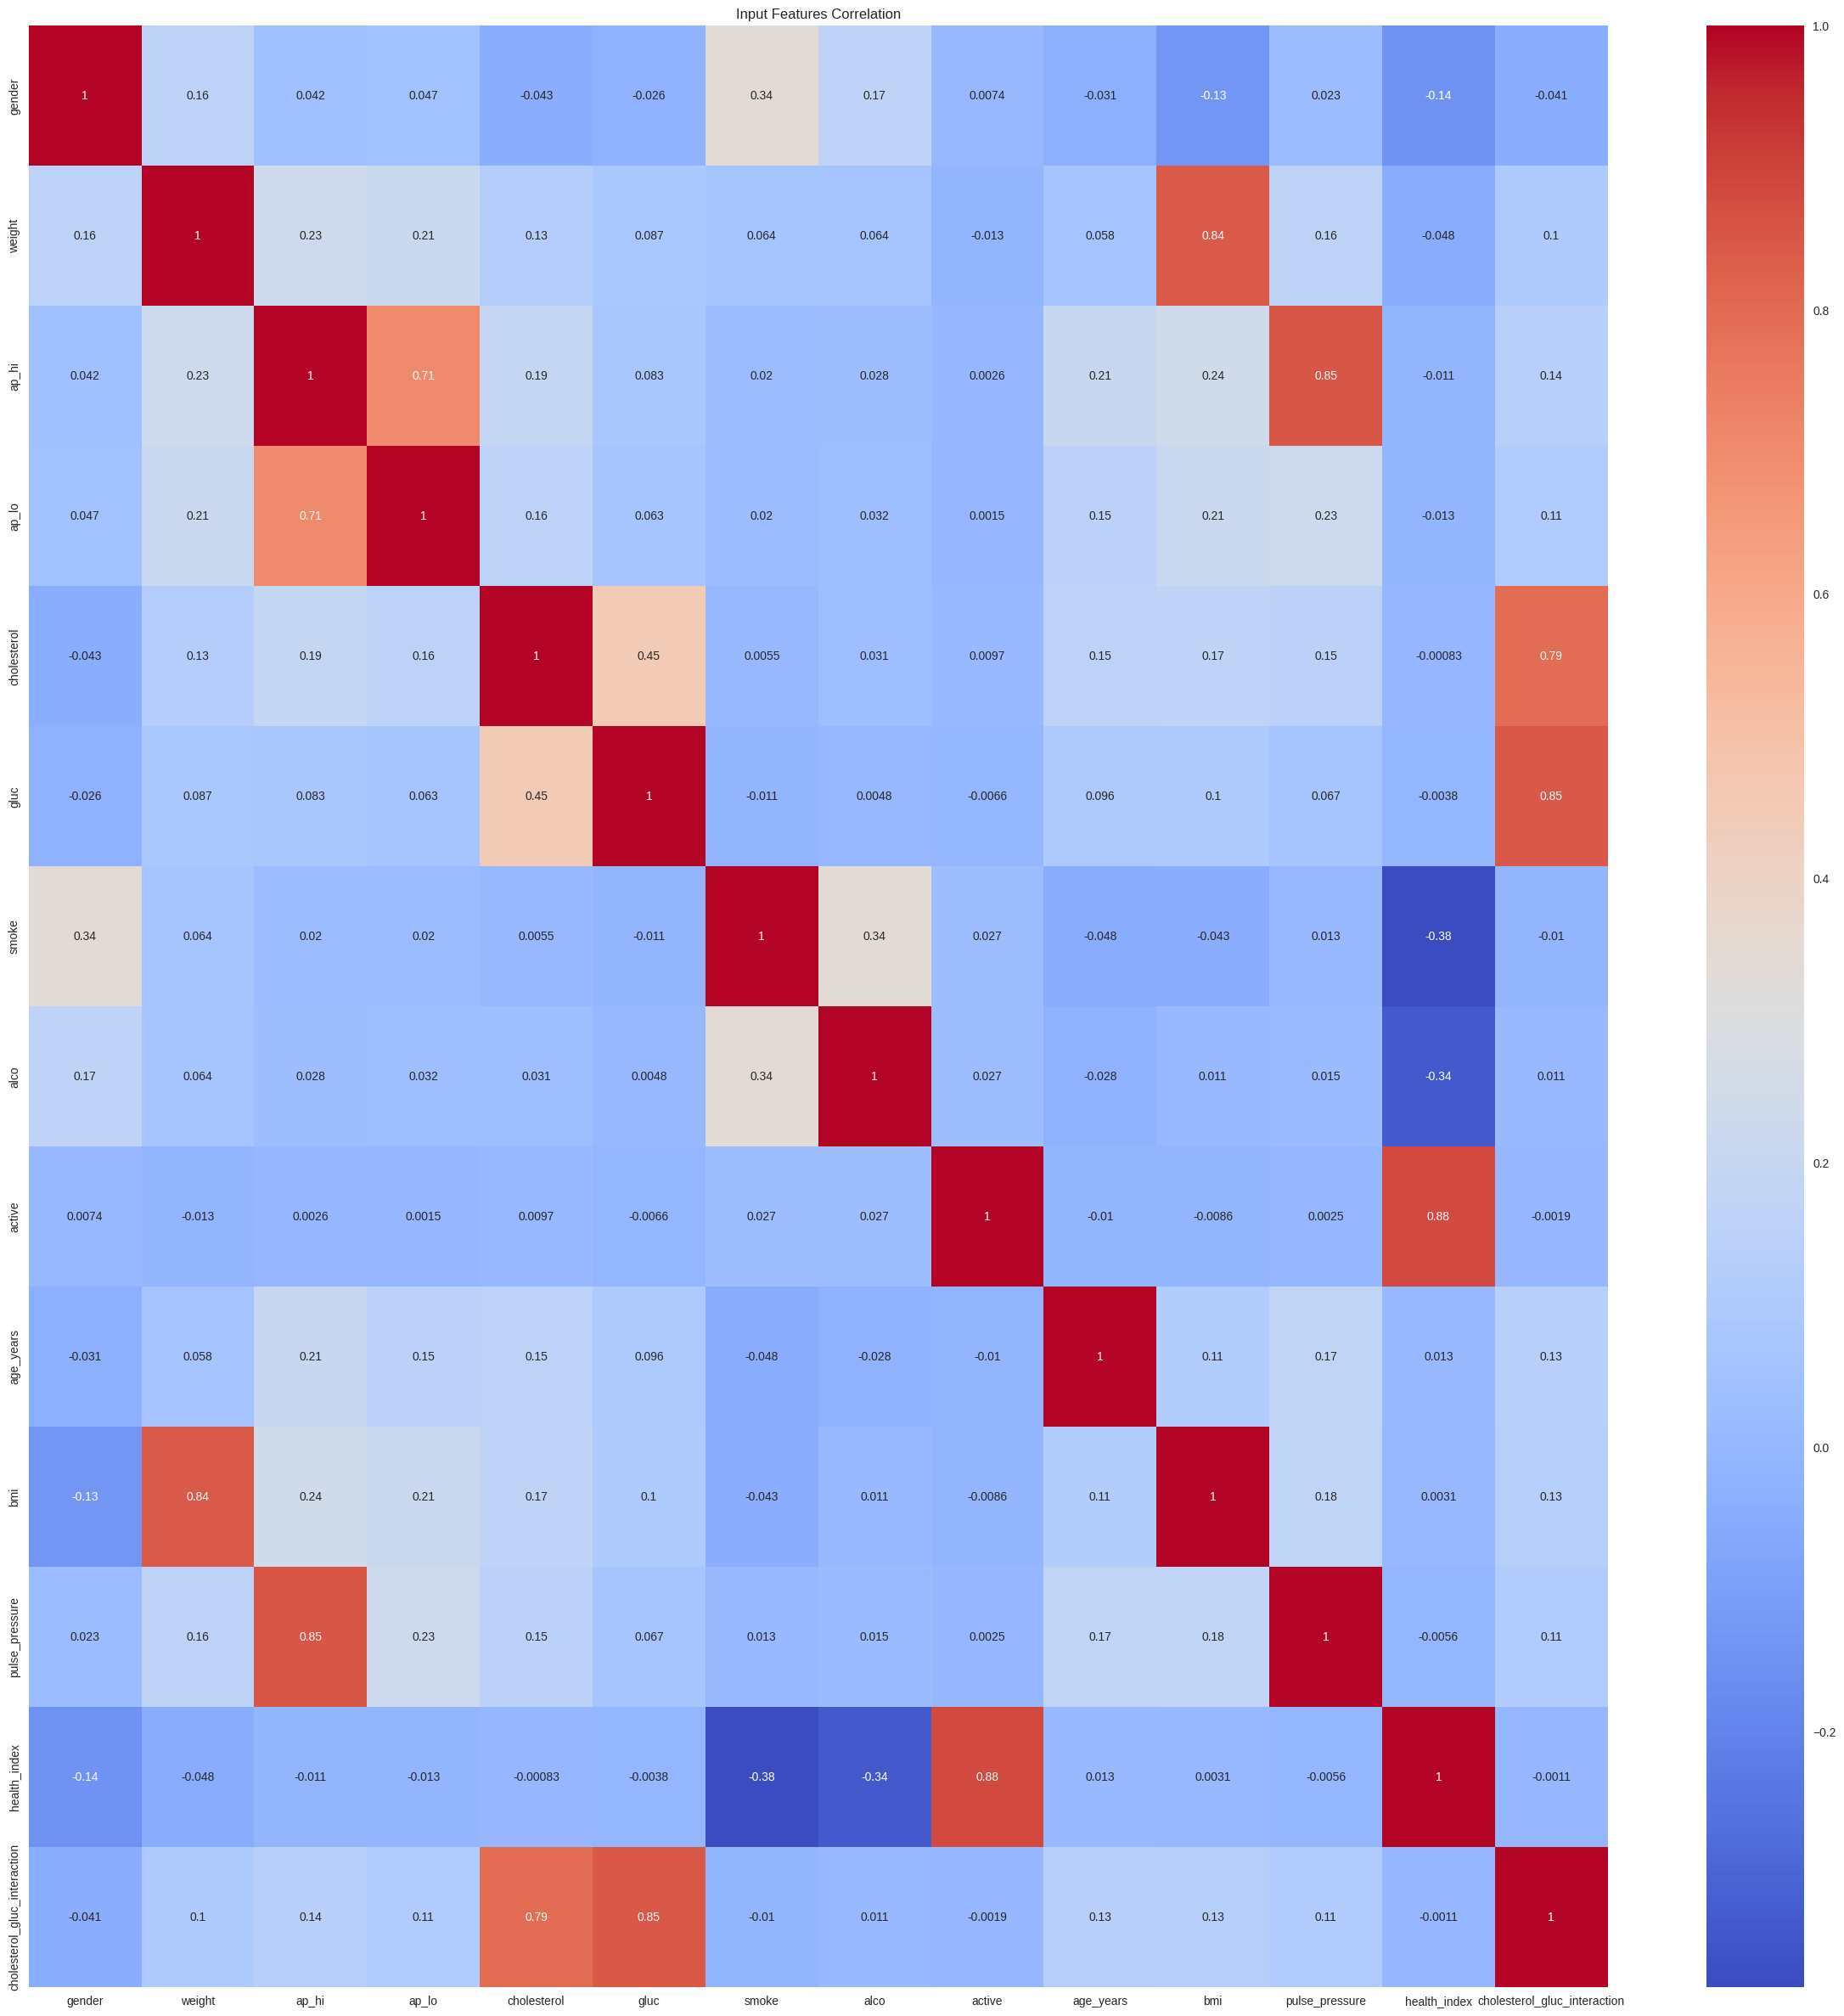

In [111]:
plt.figure(figsize=(30, 30))

plt.title("Input Features Correlation")

sns.heatmap(
    df[INPUT_FEATURES].corr(),
    annot=True,
    cmap='coolwarm',
    )

plt.show()

Min-max scaling happens after eda to not mess up visualizations and after feature engineering to not distort values

In [112]:
min_max_scaler = MinMaxScaler()
exclude = ['gluc','alco','smoke','cholesterol','active','cardio']
cols_to_scale = [col for col in df.columns if col not in exclude]
df[cols_to_scale] = min_max_scaler.fit_transform(df[cols_to_scale])